In [55]:
import os, time, json, pathlib, random, copy
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision
from torchvision import models
from torchvision.transforms import v2
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_fscore_support, accuracy_score
from PIL import Image

TEAM_ID = "T10"
SEED, IMG, BATCH = 42, 224, 32
CLASS_NAMES = ["glioma", "meningioma", "notumor", "pituitary"]
DATA_ROOT = pathlib.Path("../data")
MODEL_DIR = pathlib.Path("../model"); MODEL_DIR.mkdir(exist_ok=True)
ASSETS = pathlib.Path("report_assets"); ASSETS.mkdir(exist_ok=True)   # figures for the report
NUM_WORKERS = 2
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed(SEED)
print("torch", torch.__version__, "| torchvision", torchvision.__version__, "| GPUs:", [torch.cuda.get_device_name(i) for i in range(torch.cuda.device_count())])

torch 2.11.0+cu128 | torchvision 0.26.0+cu128 | GPUs: ['Tesla T4', 'Tesla T4']


## 1. Data and split
The split is read from `splits.csv`, written by the TensorFlow notebook, so both frameworks train, validate and test on identical images (`Testing/` is the held-out test set, `Training/` split 85/15 stratified).

In [56]:
splits = pd.read_csv("/kaggle/working/Medical-Image-Classification/notebooks/splits.csv")
splits["path"] = splits.path.map(lambda p: str(DATA_ROOT / p.replace("\\", "/")))
train, val, test = (splits[splits.split == s].reset_index(drop=True) for s in ["train", "val", "test"])

summary = pd.DataFrame({n: d.y.map(dict(enumerate(CLASS_NAMES))).value_counts() for n, d in
                        [("train", train), ("val", val), ("test", test)]}).T[CLASS_NAMES]
summary["total"] = summary.sum(axis=1); display(summary)

y,glioma,meningioma,notumor,pituitary,total
train,1190,1190,1190,1190,4760
val,210,210,210,210,840
test,400,400,400,400,1600


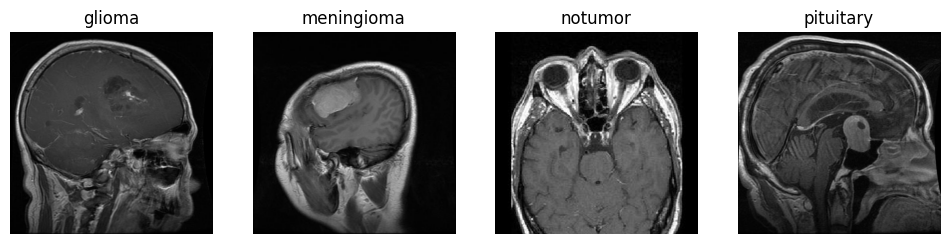

In [57]:
# Augmentation (train only), same magnitudes as the TF notebook: Keras RandomRotation(0.05) = +-0.05*360 = +-18 deg,
# translation 5%, zoom 10%, contrast 10%. No flips, since brain orientation carries meaning.
DATA_ROOT = pathlib.Path("/kaggle/working/Medical-Image-Classification/data")
for d in (train, val, test):   # re-point paths (Training|Testing/<class>/<file>) to the real data folder
    d["path"] = d.path.map(lambda p: str(DATA_ROOT.joinpath(*pathlib.Path(p).parts[-3:])))

AUG = v2.Compose([v2.RandomAffine(degrees=18, translate=(0.05, 0.05), scale=(0.9, 1.1), interpolation=v2.InterpolationMode.BILINEAR),
                  v2.ColorJitter(contrast=0.1)])

class MRI(Dataset):
    def __init__(self, df, training=False):
        self.p, self.y, self.aug = df.path.values, df.y.values, (AUG if training else None)
    def __len__(self): return len(self.p)
    def __getitem__(self, i):
        img = np.asarray(Image.open(self.p[i]).convert("RGB").resize((IMG, IMG), Image.BILINEAR)).copy()  # grayscale -> 3ch, uint8
        img = torch.from_numpy(img).permute(2, 0, 1)
        if self.aug: img = self.aug(img)
        return img.float(), int(self.y[i])                                                              # float32, 0..255

def make_dl(df, training=False):
    g = torch.Generator().manual_seed(SEED)
    return DataLoader(MRI(df, training), batch_size=BATCH, shuffle=training, generator=g if training else None,
                      num_workers=NUM_WORKERS, pin_memory=DEVICE.type == "cuda", persistent_workers=NUM_WORKERS > 0)

train_dl, val_dl, test_dl = make_dl(train, True), make_dl(val), make_dl(test)

fig, ax = plt.subplots(1, 4, figsize=(12, 3))
for i, c in enumerate(CLASS_NAMES):
    ax[i].imshow(Image.open(train[train.y == i].path.iloc[0]).convert("RGB")); ax[i].set_title(c); ax[i].axis("off")
plt.savefig(ASSETS/"pt_samples.png", dpi=150, bbox_inches="tight"); plt.show()

## 2. Model
Preprocessing lives **inside** the model (`prep`: `(x - mean) / std` with the ImageNet mean/std, exactly the ResNet50/MobileNetV2 torchvision preprocessing), so serving only needs to resize to 224x224 and feed raw 0-255 RGB. Augmentation is active only in training: small rotation, shift, zoom and contrast. No flips, since brain orientation carries meaning.

In [58]:
IMAGENET_MEAN, IMAGENET_STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)
ARCHS = {"resnet50": (models.resnet50, models.ResNet50_Weights.IMAGENET1K_V1),
         "mobilenetv2": (models.mobilenet_v2, models.MobileNet_V2_Weights.IMAGENET1K_V1)}

class Net(nn.Module):
    def __init__(self, base, c, dropout):
        super().__init__()
        self.register_buffer("mean", torch.tensor(IMAGENET_MEAN).view(1, 3, 1, 1) * 255)
        self.register_buffer("std", torch.tensor(IMAGENET_STD).view(1, 3, 1, 1) * 255)
        self.base, self.gap, self.drop = base, nn.AdaptiveAvgPool2d(1), nn.Dropout(dropout)
        self.out = nn.Linear(c, len(CLASS_NAMES))
    def prep(self, x): return (x - self.mean) / self.std
    def forward(self, x):                                     # raw 0-255 NCHW -> logits
        return self.out(self.drop(self.gap(self.base(self.prep(x))).flatten(1)))

def build_model(arch, dropout=0.3):
    ctor, w = ARCHS[arch]
    m = ctor(weights=w)
    if arch == "resnet50":
        base, c = nn.Sequential(m.conv1, m.bn1, m.relu, m.maxpool, m.layer1, m.layer2, m.layer3, m.layer4), 2048
    else:
        base, c = m.features, 1280
    for p in base.parameters(): p.requires_grad = False
    model = Net(base, c, dropout).to(DEVICE)
    return model, model.base

class EpochTimer:
    def __init__(self): self.times = []

def count_params(m):   # like Keras count_params: weights + BatchNorm running stats
    return sum(p.numel() for p in m.parameters()) + sum(b.numel() for n, b in m.named_buffers() if "running" in n)

def set_train_mode(model, finetune):
    model.train(); model.base.train(finetune)
    for m in model.base.modules():
        if isinstance(m, nn.BatchNorm2d): m.eval()             # BatchNorm always in inference mode

@torch.no_grad()
def predict(model, dl):
    model.eval(); dev = next(model.parameters()).device
    return torch.cat([F.softmax(model(x.to(dev)), 1).cpu() for x, _ in dl]).numpy()

def evaluate(model, dl, y_true):
    prob = predict(model, dl); y_pred = prob.argmax(1)
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    return dict(accuracy=accuracy_score(y_true, y_pred), precision=p, recall=r, f1=f), y_pred, prob

def run_epoch(model, dl, opt=None):
    loss_sum = correct = n = 0
    with torch.set_grad_enabled(opt is not None):
        for x, y in dl:
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            logits = model(x); loss = F.cross_entropy(logits, y)
            if opt is not None:
                opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
            loss_sum += loss.item() * len(y); correct += (logits.argmax(1) == y).sum().item(); n += len(y)
    return loss_sum / n, correct / n

def fit(model, lr, start, stop, finetune, timer, patience=4):
    """One phase: Adam, ReduceLROnPlateau(0.3, 2), EarlyStopping(4, restore best) on val loss, like the Keras callbacks."""
    opt = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="min", factor=0.3, patience=2, threshold=1e-4, threshold_mode="abs")
    h = {k: [] for k in ["loss", "accuracy", "val_loss", "val_accuracy"]}
    best, best_w, wait = float("inf"), None, 0
    for e in range(start, stop):
        t0 = time.perf_counter()
        set_train_mode(model, finetune); tl, ta = run_epoch(model, train_dl, opt)
        model.eval(); vl, va = run_epoch(model, val_dl)
        timer.times.append(time.perf_counter() - t0)
        for k, v in zip(h, [tl, ta, vl, va]): h[k].append(v)
        print(f"Epoch {e+1}/{stop} - {timer.times[-1]:.0f}s - loss: {tl:.4f} - accuracy: {ta:.4f} - val_loss: {vl:.4f} - val_accuracy: {va:.4f} - lr: {opt.param_groups[0]['lr']:.2e}")
        sched.step(vl)
        if vl < best: best, wait, best_w = vl, 0, {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= patience: break
    model.load_state_dict(best_w)
    return h

def train_arch(arch, lr1=1e-3, lr2=1e-5, ep1=5, ep2=15, unfreeze=40, dropout=0.3):
    """Phase 1: frozen backbone, train head. Phase 2: unfreeze top layers (BatchNorm kept frozen), low LR."""
    model, base = build_model(arch, dropout)
    timer = EpochTimer()
    h1 = fit(model, lr1, 0, ep1, False, timer)
    phase1 = evaluate(model, test_dl, test.y.values)[0]

    leaves = [m for m in base.modules() if not list(m.children())]
    for m in leaves[-unfreeze:]:
        if not isinstance(m, nn.BatchNorm2d):
            for p in m.parameters(): p.requires_grad = True
    h2 = fit(model, lr2, len(h1["loss"]), ep1 + ep2, True, timer)
    hist = {k: h1[k] + h2[k] for k in h1}
    return dict(arch=arch, model=model, base=base, hist=hist, phase1_epochs=len(h1["loss"]),
                phase1_test=phase1, epoch_times=timer.times, params=count_params(model),
                hp=dict(lr1=lr1, lr2=lr2, ep1=ep1, ep2=ep2, unfreeze=unfreeze, dropout=dropout, batch=BATCH))

## 3. Train: ResNet50V2 (main) and MobileNetV2 (architecture comparison)

In [59]:
runs = {}
runs["resnet50"] = train_arch("resnet50")

Epoch 1/5 - 22s - loss: 0.6419 - accuracy: 0.7592 - val_loss: 0.4762 - val_accuracy: 0.8048 - lr: 1.00e-03
Epoch 2/5 - 22s - loss: 0.4452 - accuracy: 0.8378 - val_loss: 0.3849 - val_accuracy: 0.8464 - lr: 1.00e-03
Epoch 3/5 - 22s - loss: 0.3968 - accuracy: 0.8521 - val_loss: 0.3629 - val_accuracy: 0.8583 - lr: 1.00e-03
Epoch 4/5 - 21s - loss: 0.3920 - accuracy: 0.8523 - val_loss: 0.3426 - val_accuracy: 0.8714 - lr: 1.00e-03
Epoch 5/5 - 22s - loss: 0.3753 - accuracy: 0.8586 - val_loss: 0.3135 - val_accuracy: 0.8881 - lr: 1.00e-03
Epoch 6/20 - 26s - loss: 0.3033 - accuracy: 0.8847 - val_loss: 0.2327 - val_accuracy: 0.9190 - lr: 1.00e-05
Epoch 7/20 - 26s - loss: 0.1984 - accuracy: 0.9275 - val_loss: 0.1541 - val_accuracy: 0.9476 - lr: 1.00e-05
Epoch 8/20 - 26s - loss: 0.1407 - accuracy: 0.9475 - val_loss: 0.1958 - val_accuracy: 0.9345 - lr: 1.00e-05
Epoch 9/20 - 27s - loss: 0.1032 - accuracy: 0.9609 - val_loss: 0.1327 - val_accuracy: 0.9560 - lr: 1.00e-05
Epoch 10/20 - 27s - loss: 0.0905 

In [60]:
runs["mobilenetv2"] = train_arch("mobilenetv2")

Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-b0353104.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 110MB/s] 


Epoch 1/5 - 20s - loss: 0.6210 - accuracy: 0.7744 - val_loss: 0.4085 - val_accuracy: 0.8524 - lr: 1.00e-03
Epoch 2/5 - 20s - loss: 0.4068 - accuracy: 0.8525 - val_loss: 0.3500 - val_accuracy: 0.8714 - lr: 1.00e-03
Epoch 3/5 - 20s - loss: 0.3589 - accuracy: 0.8670 - val_loss: 0.3310 - val_accuracy: 0.8821 - lr: 1.00e-03
Epoch 4/5 - 20s - loss: 0.3462 - accuracy: 0.8712 - val_loss: 0.2919 - val_accuracy: 0.8905 - lr: 1.00e-03
Epoch 5/5 - 20s - loss: 0.3218 - accuracy: 0.8819 - val_loss: 0.2812 - val_accuracy: 0.8952 - lr: 1.00e-03
Epoch 6/20 - 20s - loss: 0.2988 - accuracy: 0.8887 - val_loss: 0.3041 - val_accuracy: 0.8821 - lr: 1.00e-05
Epoch 7/20 - 20s - loss: 0.2518 - accuracy: 0.9097 - val_loss: 0.2304 - val_accuracy: 0.9155 - lr: 1.00e-05
Epoch 8/20 - 20s - loss: 0.2229 - accuracy: 0.9145 - val_loss: 0.2235 - val_accuracy: 0.9214 - lr: 1.00e-05
Epoch 9/20 - 20s - loss: 0.1991 - accuracy: 0.9239 - val_loss: 0.1819 - val_accuracy: 0.9250 - lr: 1.00e-05
Epoch 10/20 - 20s - loss: 0.1843 

## 4. Evaluation

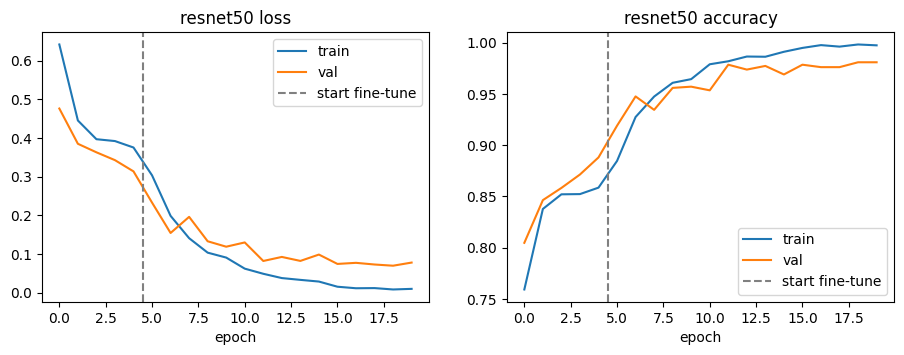

=== resnet50 (test) ===
              precision    recall  f1-score   support

      glioma     0.9850    0.8225    0.8965       400
  meningioma     0.8912    0.9625    0.9255       400
     notumor     0.9368    1.0000    0.9674       400
   pituitary     0.9730    0.9900    0.9814       400

    accuracy                         0.9437      1600
   macro avg     0.9465    0.9438    0.9427      1600
weighted avg     0.9465    0.9437    0.9427      1600



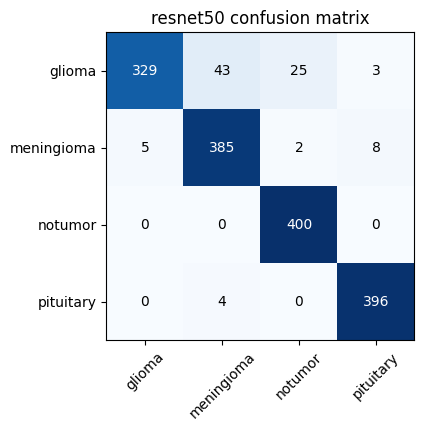

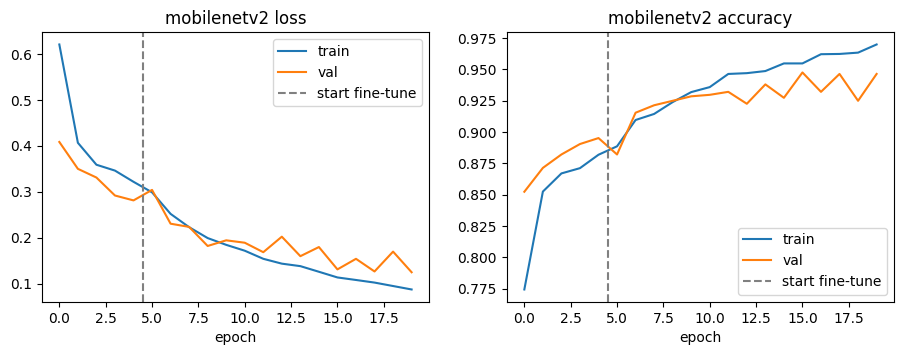

=== mobilenetv2 (test) ===
              precision    recall  f1-score   support

      glioma     0.9451    0.7750    0.8516       400
  meningioma     0.8430    0.8725    0.8575       400
     notumor     0.9238    1.0000    0.9604       400
   pituitary     0.9341    0.9925    0.9624       400

    accuracy                         0.9100      1600
   macro avg     0.9115    0.9100    0.9080      1600
weighted avg     0.9115    0.9100    0.9080      1600



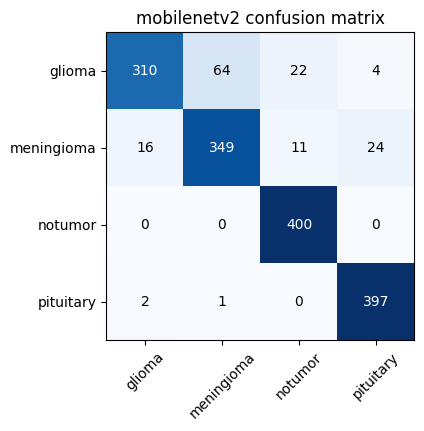

,params (M),mean s/epoch,best val acc,test acc (head only),test accuracy,test precision,test recall,test f1
resnet50,23.5693,25.5070,0.9810,0.8131,0.9438,0.9465,0.9438,0.9427
mobilenetv2,2.2631,19.6857,0.9476,0.8494,0.9100,0.9115,0.9100,0.9080


In [61]:
def plot_curves(r):
    h, k = r["hist"], r["phase1_epochs"]
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
    for a, m in zip(ax, ["loss", "accuracy"]):
        a.plot(h[m], label="train"); a.plot(h["val_" + m], label="val")
        a.axvline(k - 0.5, ls="--", c="gray", label="start fine-tune"); a.set_title(f"{r['arch']} {m}"); a.set_xlabel("epoch"); a.legend()
    plt.savefig(ASSETS/f"pt_curves_{r['arch']}.png", dpi=150, bbox_inches="tight"); plt.show()

results = {}
for name, r in runs.items():
    plot_curves(r)
    m, y_pred, prob = evaluate(r["model"], test_dl, test.y.values)
    r["test"], r["y_pred"] = m, y_pred
    print(f"=== {name} (test) ==="); print(classification_report(test.y, y_pred, target_names=CLASS_NAMES, digits=4))
    cm = confusion_matrix(test.y, y_pred)
    plt.figure(figsize=(4.5, 4)); plt.imshow(cm, cmap="Blues"); plt.title(f"{name} confusion matrix")
    plt.xticks(range(4), CLASS_NAMES, rotation=45); plt.yticks(range(4), CLASS_NAMES)
    for i in range(4):
        for j in range(4): plt.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max()/2 else "black")
    plt.savefig(ASSETS/f"pt_cm_{name}.png", dpi=150, bbox_inches="tight"); plt.show()
    results[name] = dict(params=r["params"], mean_epoch_s=float(np.mean(r["epoch_times"])), total_train_s=float(sum(r["epoch_times"])),
                         best_val_acc=float(max(r["hist"]["val_accuracy"])), test=m, test_after_phase1_only=r["phase1_test"], hp=r["hp"])

comparison = pd.DataFrame({n: {"params (M)": v["params"]/1e6, "mean s/epoch": v["mean_epoch_s"], "best val acc": v["best_val_acc"],
                               "test acc (head only)": v["test_after_phase1_only"]["accuracy"],
                               **{f"test {k}": x for k, x in v["test"].items()}} for n, v in results.items()}).T.round(4)
display(comparison)

## 5. Interpretability: Grad-CAM
Gradient of the predicted class score w.r.t. the last convolutional feature map, channel-averaged, ReLU, upsampled onto the image.

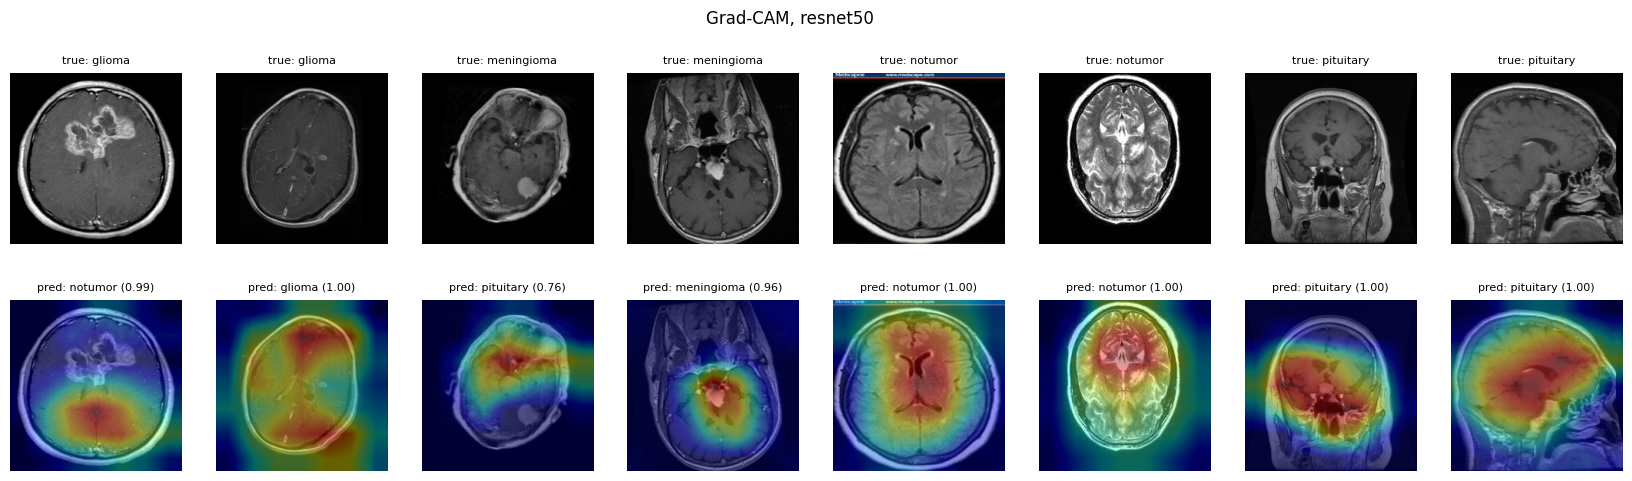

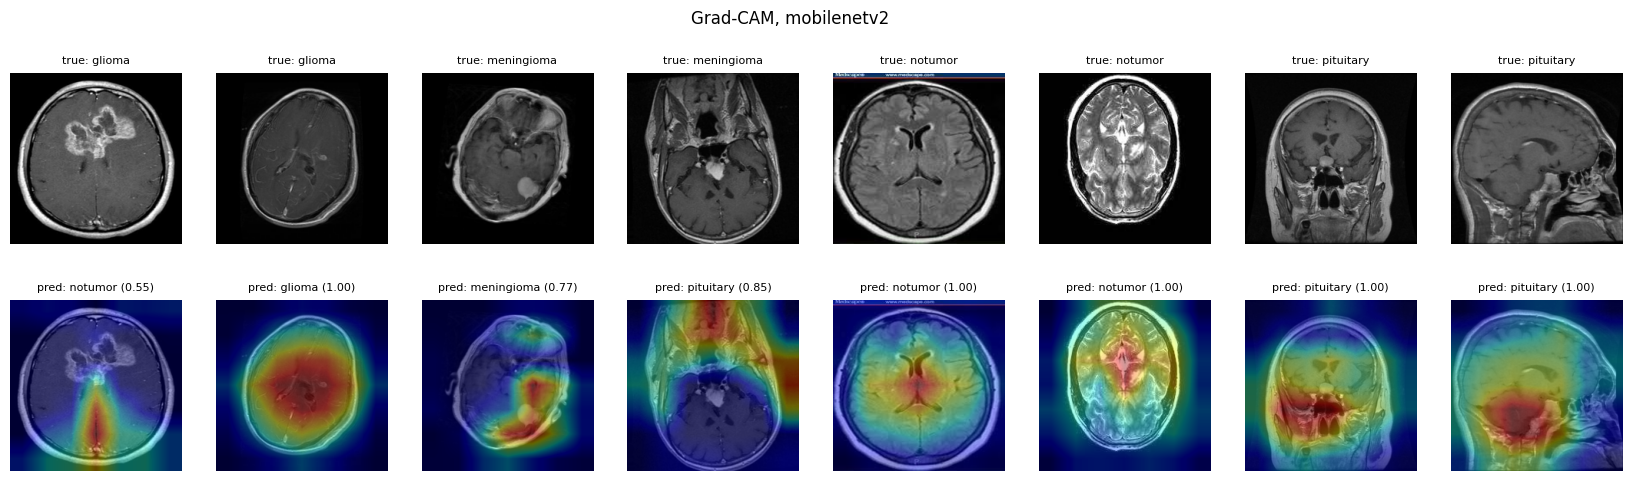

In [62]:
def make_gradcam(model):
    def cam(img, k=None):                                   # img: HWC float32, 0..255
        model.eval(); dev = next(model.parameters()).device
        x = model.prep(torch.from_numpy(img).permute(2, 0, 1)[None].to(dev)).requires_grad_(True)
        conv = model.base(x)                                # last conv feature map (7x7)
        p = F.softmax(model.out(model.drop(model.gap(conv).flatten(1))), 1)
        k = int(p[0].argmax()) if k is None else k
        g, = torch.autograd.grad(p[0, k], conv)
        w = g.mean(dim=(2, 3), keepdim=True)
        c = F.relu((w * conv).sum(1))[0]
        c = c / (c.max() + 1e-8)
        heat = F.interpolate(c[None, None], size=(IMG, IMG), mode="bilinear", align_corners=False)[0, 0]
        return heat.detach().cpu().numpy(), k, p[0].detach().cpu().numpy()
    return cam

def show_gradcam(name, n_per_class=2):
    r = runs[name]; cam = make_gradcam(r["model"])
    rows = [test[test.y == c].iloc[i] for c in range(4) for i in range(n_per_class)]
    fig, ax = plt.subplots(2, len(rows), figsize=(2.6 * len(rows), 5.4))
    for j, row in enumerate(rows):
        img = np.asarray(Image.open(row.path).convert("RGB").resize((IMG, IMG)), dtype="float32")
        heat, k, p = cam(img)
        ax[0, j].imshow(img.astype("uint8")); ax[0, j].set_title(f"true: {CLASS_NAMES[row.y]}", fontsize=8); ax[0, j].axis("off")
        ax[1, j].imshow(img.astype("uint8")); ax[1, j].imshow(heat, cmap="jet", alpha=0.4)
        ax[1, j].set_title(f"pred: {CLASS_NAMES[k]} ({p[k]:.2f})", fontsize=8); ax[1, j].axis("off")
    plt.suptitle(f"Grad-CAM, {name}"); plt.savefig(ASSETS/f"pt_gradcam_{name}.png", dpi=150, bbox_inches="tight"); plt.show()

for n in runs: show_gradcam(n)

## 6. Pick the model to export and verify serving parity
Selection by **validation** accuracy (not test). The model is exported as TorchScript (`.pt`), so the FastAPI service needs only `torch` (no class definition). The check below runs the exact preprocessing a FastAPI service will use (PIL, RGB, bilinear resize to 224, raw 0-255 floats) and compares it with the training pipeline.

In [63]:
best = max(runs, key=lambda n: results[n]["best_val_acc"]); print("selected by val acc:", best)
for r in runs.values(): r["model"].to("cpu").eval()
model = runs[best]["model"]

def serve_pre(p):   # <- copy this into app/main.py
    return np.asarray(Image.open(p).convert("RGB").resize((IMG, IMG), Image.BILINEAR), dtype="float32")
def to_batch(arrs): return torch.from_numpy(np.stack(arrs)).permute(0, 3, 1, 2).contiguous()   # NHWC -> NCHW

path = MODEL_DIR / f"model_{TEAM_ID}.pt"
torch.jit.save(torch.jit.trace(model, to_batch([serve_pre(test.path.iloc[0])])), str(path))
print(f"saved {path}  ({path.stat().st_size/1e6:.1f} MB)")

reloaded = torch.jit.load(str(path), map_location="cpu").eval()
with torch.inference_mode():
    pred = np.concatenate([reloaded(to_batch([serve_pre(p) for p in test.path.values[i:i+64]])).argmax(1).numpy()
                           for i in range(0, len(test), 64)])
print("test acc via PIL serving path:", accuracy_score(test.y, pred), "| training-pipeline acc:", results[best]["test"]["accuracy"])

selected by val acc: resnet50
saved ../model/model_T10.pt  (94.7 MB)
test acc via PIL serving path: 0.94375 | training-pipeline acc: 0.94375


In [64]:
lat = {}
x = to_batch([serve_pre(test.path.iloc[0])])
with torch.inference_mode():
    for n, r in runs.items():
        r["model"](x)                                       # warm-up
        t0 = time.perf_counter()
        for _ in range(50): r["model"](x).numpy()
        lat[n] = (time.perf_counter() - t0) / 50 * 1000
for n in results: results[n]["cpu_latency_ms"] = lat[n]
print({n: f"{v:.1f} ms" for n, v in lat.items()})

results["_meta"] = dict(selected=best, torch=torch.__version__, torchvision=torchvision.__version__,
                        gpus=[torch.cuda.get_device_name(i) for i in range(torch.cuda.device_count())],
                        split=summary.to_dict("index"))
json.dump(results, open(ASSETS/"pt_results.json", "w"), indent=2, default=float)

{'resnet50': '110.1 ms', 'mobilenetv2': '21.0 ms'}


## 7. Notes for the report
- **Split:** table in section 1. Identical to the TensorFlow notebook (`splits.csv`), so both frameworks see the same train, validation and test images. Model selection and early stopping use validation only; the test set is used only for reporting.
- **Preprocessing:** grayscale to 3 channels, bilinear resize to 224x224, ImageNet mean/std applied inside the model. Serving uses the same PIL resize, and the parity check in section 6 compares the exported model against the training pipeline.
- **Augmentation (training only):** rotation +-18 deg, 5% shift, 10% zoom, 10% contrast. No flips, since orientation carries meaning in brain MRI.
- **Transfer learning:** ImageNet backbone. Phase 1 trains only the new head (lr 1e-3, 5 epochs). Phase 2 unfreezes the last 40 backbone layers with BatchNorm frozen (lr 1e-5, up to 15 epochs). Early stopping on validation loss, best weights restored.
- **Strategy and architecture comparison:** `test_after_phase1_only` vs the final test metrics in `pt_results.json` shows what fine-tuning added over a frozen backbone. ResNet50 vs MobileNetV2: parameters, s/epoch, CPU latency, accuracy and F1.
- **Framework differences to discuss:**
  - Backbone: ResNet50 v1.5 (torchvision) vs ResNet50V2 (Keras), with different pretrained weights, so accuracy gaps are not purely a framework effect.
  - Training: explicit loop (more code, full control, easy to inspect tensors) vs `model.fit` with callbacks.
  - Normalization: ImageNet mean/std vs [-1, 1].
  - Augmentation: black fill vs reflect fill.
  - Export: TorchScript `.pt` (no class definition needed to load) vs `.keras`.
  - Speed: comparable only if both notebooks ran on the same hardware. Data loading also differs (PyTorch caches resized images in RAM, TF reads from disk each epoch).
- **Limitations:**
  - Dataset: one public compilation from several sources. Scanner and protocol variety is uncontrolled, and we did not verify the labels clinically.
  - 2D slices with no patient IDs, so slices from the same patient may appear in both train and test. This is possible leakage and may make test scores optimistic.
  - Only 4 classes, and no external validation set.
  - One run with one seed, so differences in stability between runs or frameworks are not measured.
  - Grad-CAM maps are 7x7, so localization is coarse, and they are qualitative evidence only.
  - This is a coursework model, not a diagnostic tool.